# 1.2 - Limpieza y validación de viajes MiBici

**Equipo 9 · MLOps**

## Objetivo y definición de demanda

Preparar los registros de viajes para estimar demanda por estación o zona y hora, aplicando reglas
explícitas de integridad, consistencia temporal y plausibilidad del desplazamiento.

La unidad de análisis es **un registro de viaje**. Para esta preparación, la demanda se define como
el número de inicios de viajes que cumplen las reglas de aceptación. Esta definición permite distinguir
los desplazamientos de registros duplicados, errores temporales y posibles intentos fallidos de desanclaje.
Su interpretación operativa deberá validarse con el equipo antes del modelado.

## Justificación general de la limpieza

Cada registro aceptado contribuye al conteo de demanda. Una copia puede inflarlo; una fecha incorrecta
puede asignarlo a otra hora; una estación sin ubicación impide asignarlo con certeza a una zona.
Por ello, la limpieza verifica primero la integridad del registro y después su plausibilidad según el dominio.

Se conservan dos vistas: **anotada**, que mantiene todos los registros con sus indicadores de calidad y
motivos de exclusión; y **válida**, que contiene los registros aceptados por la política configurada.
Los atributos demográficos corregidos conservan una columna con su valor original y los CSV de entrada
permanecen intactos. Esto permite auditar las decisiones y reconsiderar exclusiones con nueva evidencia.

Los límites de duración, velocidad y edad son decisiones metodológicas configurables. Su función es
establecer criterios reproducibles; no demuestran por sí solos que cada registro señalado sea un error.


## 1. Definición y justificación de las reglas

Las reglas de **integridad** permiten identificar y ubicar un viaje de manera consistente. Las reglas
de **plausibilidad** evalúan si su duración y desplazamiento son compatibles con el uso esperado del
servicio. La política predeterminada aplica ambos grupos; los indicadores se conservan para revisar su efecto.

| Regla | Condición y acción | Justificación |
|---|---|---|
| Unicidad del registro | Para copias idénticas en las columnas del contrato, conservar una y marcar las restantes. | Un mismo viaje debe contribuir una sola vez al conteo de demanda. |
| Coherencia del identificador | Si un ID tiene valores distintos dentro del mes, poner todas sus filas en cuarentena. También poner en cuarentena los IDs presentes en varios archivos. | Evita seleccionar una versión arbitraria y permite investigar duplicación entre archivos o reutilización de IDs. |
| Identificadores esenciales | Excluir registros sin ID de viaje, origen o destino. | Se necesita identificar el evento y sus estaciones para aplicar el contrato de esta vista de viajes. |
| Fechas interpretables | Excluir registros cuyo inicio o fin no pueda interpretarse como fecha. | Sin ambos instantes no puede calcularse una duración válida; sin inicio tampoco puede asignarse la demanda a una hora. |
| Correspondencia con el periodo | Excluir registros cuyo inicio no pertenezca al mes del archivo. | Mantiene consistente la partición mensual y evita incorporar eventos de otro periodo. Se conserva el registro anotado para investigar su archivo correcto. |
| Duración positiva | Excluir registros con duración menor o igual a cero. | La definición adoptada requiere un intervalo de uso positivo; tiempos nulos o negativos no permiten interpretar un desplazamiento de forma consistente. |
| Viaje muy corto en la misma estación | Marcar y excluir por defecto cuando origen y destino coincidan y la duración sea menor a 60 s. | Puede corresponder a un intento fallido o cambio de bicicleta. Es una hipótesis operativa que debe contrastarse; el registro permanece disponible para revisión. |
| Estaciones identificables | Marcar y excluir por defecto si origen o destino no aparecen en el catálogo seleccionado. | La asignación geográfica depende de conocer las estaciones. La ausencia en el catálogo no prueba que el viaje no existió. |
| Coordenadas utilizables | Marcar y excluir por defecto estaciones catalogadas con coordenadas ausentes, no numéricas, no finitas o fuera de rangos geográficos válidos. | Sin ubicación utilizable no puede calcularse la distancia ni comprobarse la asignación espacial. |
| Velocidad plausible | Calcular distancia Haversine dividida entre duración; marcar y excluir por defecto velocidades mayores a 30 km/h. | Un desplazamiento demasiado rápido puede indicar errores de tiempo, estación o registro. El umbral debe revisarse con evidencia operativa, especialmente para bicicletas eléctricas. |
| Duración máxima | Marcar y excluir por defecto viajes mayores a 180 min. | Un uso tan prolongado puede reflejar una devolución no registrada o un préstamo excepcional. El límite delimita la población de viajes analizada y se evalúa con sensibilidad. |
| Edad plausible | Si la edad calculada no está entre 16 y 90 años, convertir el año de nacimiento a faltante y conservar su valor original. Conservar el viaje. | Los extremos se tratan como datos demográficos por revisar; no invalidan por sí mismos el evento que contribuye a demanda. El rango es una decisión de calidad, no una comprobación de elegibilidad. |
| Género y demografía faltante | Permitir faltantes; convertir categorías distintas de M/F a faltante, conservando el valor original y el viaje. | Estos atributos no son necesarios para contar inicios de viajes. No se imputan características personales sin evidencia. M/F es el contrato de categorías adoptado para estos archivos. |
| Volumen diario bajo | Marcar días con menos del 60% de la mediana del mismo día de semana en su mes; no excluir automáticamente. | Una caída de volumen justifica investigación, pero no distingue entre festivo, falla, clima o menor demanda real. |

**Límites exactos:** 60 s no se considera viaje corto; 180 min no supera la duración máxima;
30 km/h no supera la velocidad máxima. Los viajes cortos entre estaciones diferentes se evalúan por
su velocidad y las demás reglas, sin descartarlos solo por durar menos de un minuto.

**Alcance espacial:** exigir origen y destino conocidos define una vista apta para analizar el viaje
completo. Para un objetivo limitado a salidas por estación podría evaluarse otra política que conserve
viajes con origen conocido y destino sin catálogo, documentando ese cambio de definición.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, hashlib, platform, gc, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_DIR = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / 'proyecto_mlops_equipo_9' / 'dataset.py').is_file()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Abre el notebook desde la raíz del proyecto o notebooks/.')
sys.path.insert(0, str(PROJECT_DIR)) if str(PROJECT_DIR) not in sys.path else None
from proyecto_mlops_equipo_9.dataset import cargar_mes, cargar_estaciones, columnas_mes, COLUMNAS, ruta_viajes

MESES = sorted(p.stem.removeprefix('datos_abiertos_')
               for p in (PROJECT_DIR / 'data/raw/viajes').glob('datos_abiertos_*.csv'))
if not MESES:
    raise FileNotFoundError('No hay CSV mensuales en data/raw/viajes. Descarga los datos primero.')
CATALOGO = PROJECT_DIR / 'data/raw/estaciones/nomenclatura_2026_09.csv'
if not CATALOGO.is_file():
    raise FileNotFoundError(f'No existe el catálogo fijado: {CATALOGO}. Selecciona una versión explícita.')

from proyecto_mlops_equipo_9.cleaning import POLITICA_DEFAULT
POLITICA = dict(POLITICA_DEFAULT)
# Desactivado para ejecutar el análisis sin generar millones de filas en disco.
# Al activarlo, cada corrida usa una carpeta nueva; nunca sobrescribe datos anteriores.
EXPORTAR_DATOS = False
REGISTRAR_MLFLOW = False
if REGISTRAR_MLFLOW and not EXPORTAR_DATOS:
    raise ValueError('Activa EXPORTAR_DATOS para registrar una versión materializada en MLflow.')

pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 30)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Proyecto: {PROJECT_DIR.name}; meses: {len(MESES)} ({MESES[0]} a {MESES[-1]})')
display(pd.Series(POLITICA, name='valor').to_frame())


2026-10-23 22:36:53.593 | INFO     | proyecto_mlops_equipo_9.config:<module>:11 - PROJ_ROOT path is: C:\Users\ferur\Documents\Tec_de_monterrey\Maestria_Inteligencia_Artificial\11MLOps\PROYECTO\Personal\Proyecto_MLOPS_Equipo_9


Proyecto: Proyecto_MLOPS_Equipo_9; meses: 21 (2025_01 a 2026_09)


,valor
version_metodologia,1.0.0
min_misma_estacion_s,60
max_velocidad_kmh,30
max_duracion_min,180
edad_min,16
edad_max,90
umbral_dia_bajo,0.6
excluir_misma_estacion_corta,True
excluir_estacion_sin_catalogo,True
excluir_sin_coordenadas,True


## 2. Insumos, catálogo y diagnóstico de todos los meses

Se exige el esquema esperado en cada archivo antes de limpiar. Se conserva el catálogo histórico con
estaciones `ex-`; el prefijo no prueba que un viaje histórico sea inválido. Se comprueba unicidad del ID
del catálogo y validez de coordenadas. Las huellas SHA-256 identifican los archivos realmente leídos.

La primera pasada calcula calidad y detecta IDs compartidos por archivos mensuales. Solo se retienen
vectores de IDs y resúmenes; la segunda pasada limpia un mes a la vez. Los IDs compartidos se ponen en
cuarentena para revisar si existe duplicación entre archivos o reutilización de identificadores.


In [2]:
def sha256_archivo(ruta):
    h = hashlib.sha256()
    with Path(ruta).open('rb') as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()

esquema = pd.DataFrame([{'mes': m, 'coincide': columnas_mes(m) == COLUMNAS} for m in MESES])
if not esquema['coincide'].all():
    raise ValueError(f"Esquemas incompatibles: {esquema.loc[~esquema['coincide'], 'mes'].tolist()}")
estaciones = cargar_estaciones(CATALOGO)
if estaciones['id'].isna().any() or estaciones['id'].duplicated().any():
    raise ValueError('El catálogo debe tener IDs únicos y no nulos.')
coords = estaciones.set_index('id')[['latitude', 'longitude']].apply(pd.to_numeric, errors='coerce')
coord_valida = (np.isfinite(coords).all(axis=1) & coords['latitude'].between(-90, 90)
                & coords['longitude'].between(-180, 180))
coords.loc[~coord_valida, :] = np.nan
manifest_entradas = []
calidad = []
vectores_ids = []
for mes in MESES:
    ruta = ruta_viajes(mes)
    huella = sha256_archivo(ruta)
    raw = cargar_mes(mes)
    # Se releerá en la segunda pasada y se comprobará que la huella no cambió.
    manifest_entradas.append({'tipo': 'viajes', 'mes': mes, 'archivo': ruta.name,
                              'bytes': ruta.stat().st_size, 'sha256': huella})
    unicos = raw.drop_duplicates(subset=COLUMNAS)
    vectores_ids.append(unicos['viaje_id'].dropna().drop_duplicates().to_numpy())
    anio, numero = map(int, mes.split('_'))
    fuera_mes = raw['inicio'].notna() & ((raw['inicio'].dt.year != anio) | (raw['inicio'].dt.month != numero))
    calidad.append({
        'mes': mes, 'originales': len(raw), 'duplicados_exactos': int(raw.duplicated(subset=COLUMNAS).sum()),
        'ids_conflictivos_mes': int(unicos.loc[unicos['viaje_id'].duplicated(keep=False), 'viaje_id'].nunique()),
        'fechas_invalidas': int(raw[['inicio', 'fin']].isna().any(axis=1).sum()),
        'fuera_mes': int(fuera_mes.sum()), 'duracion_no_positiva': int(raw['duracion_min'].le(0).sum()),
        'genero_nulo': int(raw['genero'].isna().sum()), 'nacimiento_nulo': int(raw['anio_nacimiento'].isna().sum()),
        'cortos': int(raw['duracion_min'].ge(0).mul(raw['duracion_min'].lt(1)).sum()),
        'largos': int(raw['duracion_min'].gt(POLITICA['max_duracion_min']).sum()),
    })
    del raw, unicos
    print(f'Diagnóstico: {mes}')
todos_ids = np.concatenate(vectores_ids)
ids, frecuencias = np.unique(todos_ids, return_counts=True)
IDS_ENTRE_ARCHIVOS = set(ids[frecuencias > 1].tolist())
del todos_ids, ids, frecuencias, vectores_ids
manifest_entradas.append({'tipo': 'catalogo', 'mes': '', 'archivo': CATALOGO.name,
                         'bytes': CATALOGO.stat().st_size, 'sha256': sha256_archivo(CATALOGO)})
manifest_entradas = pd.DataFrame(manifest_entradas)
calidad = pd.DataFrame(calidad)
print(f'IDs presentes en varios archivos: {len(IDS_ENTRE_ARCHIVOS):,}')
print(f'Estaciones: {len(estaciones)}; sin coordenadas utilizables: {int((~coord_valida).sum())}')
display(calidad)


Diagnóstico: 2025_01


Diagnóstico: 2025_02


Diagnóstico: 2025_03


Diagnóstico: 2025_04


Diagnóstico: 2025_05


...

Diagnóstico: 2026_07


Diagnóstico: 2026_08


Diagnóstico: 2026_09


IDs presentes en varios archivos: 0
Estaciones: 484; sin coordenadas utilizables: 0


,mes,originales,duplicados_exactos,ids_conflictivos_mes,fechas_invalidas,fuera_mes,duracion_no_positiva,genero_nulo,nacimiento_nulo,cortos,largos
0,2025_01,380184,0,0,0,0,205,2702,147,9282,45
1,2025_02,372529,0,0,0,0,194,2982,133,9018,42
2,2025_03,405110,0,0,0,0,216,3213,176,10351,52
3,2025_04,366193,0,0,0,0,185,3483,160,9137,20
4,2025_05,395891,0,0,0,0,189,3706,96,10051,32
5,2025_06,356611,0,0,0,0,278,3333,98,9726,50
6,2025_07,368186,0,0,0,0,253,3464,38,9773,35
7,2025_08,374727,0,0,0,0,275,3452,25,10099,33
8,2025_09,376789,0,0,0,0,228,3426,29,10190,35
9,2025_10,420064,0,0,0,0,225,4343,33,10524,37


## 3. Anotación, selección y validación

La anotación registra cada condición de calidad antes de seleccionar viajes. Un registro puede activar
varios indicadores; sus conteos describen problemas potenciales y no deben sumarse como exclusiones independientes.

La selección aplica un orden explícito y atribuye cada fila excluida a su primer motivo. La bitácora
registra cuántas filas entran y salen de cada paso. El balance debe cumplir: registros originales =
registros válidos + registros excluidos.

La comparación de registros para detectar IDs conflictivos precede a la corrección demográfica. Así se
evita que dos registros distintos parezcan idénticos después de convertir atributos a faltantes.

La velocidad se calcula con distancia Haversine en línea recta, que subestima o iguala la distancia
recorrida. Una velocidad baja calculada no garantiza que el viaje sea correcto. Además, un catálogo
fijo puede no representar los cambios históricos de ubicación; estas limitaciones deben acompañar
la interpretación de las exclusiones geográficas.


In [3]:
# Una sola implementación de reglas para el notebook y las versiones silver.
from proyecto_mlops_equipo_9.cleaning import (
    anotar_viajes, reglas_seleccion, seleccionar_viajes, validar_resultado, velocidad_linea_recta,
)

### 3.1. Evidencia para las reglas de plausibilidad del viaje

La duración y la velocidad responden preguntas complementarias. En un registro que vuelve a la misma
estación, el tiempo muy corto puede indicar un intento fallido o cambio de bicicleta; entre estaciones
distintas, la duración debe evaluarse junto con la distancia. No se establece un mínimo universal de
tiempo para todos los desplazamientos.

Se estudia **junio de 2026**, si está disponible, o el último mes descargado. El detalle de un mes permite
examinar las distribuciones; no demuestra que los umbrales sean adecuados para todos los periodos.
Los indicadores mensuales de la sección 5 y la sensibilidad de la sección 6 completan la revisión.

#### Duración corta y posible desanclaje fallido

El panel izquierdo muestra **conteos absolutos** en intervalos de 10 segundos. El derecho muestra el
**porcentaje dentro de cada grupo de registros de menos de cinco minutos**; cada grupo suma 100% en
esa ventana, no en el conjunto completo de viajes. Esto permite distinguir volumen y forma sin que el
tamaño de un grupo oculte al otro.

Se observan registros originales con ambos IDs conocidos y duración finita en **[0, 300) segundos**,
antes de aplicar filtros. Los ceros se incluyen para visualizar la anomalía, aunque el pipeline los
excluye por duración no positiva antes de evaluar desanclajes. Los registros sin IDs o duración no se
clasifican en esta figura. La línea marca el umbral configurado, no una frontera comprobada entre viajes
reales y errores. La coincidencia de estación tampoco prueba por sí sola la causa del evento.

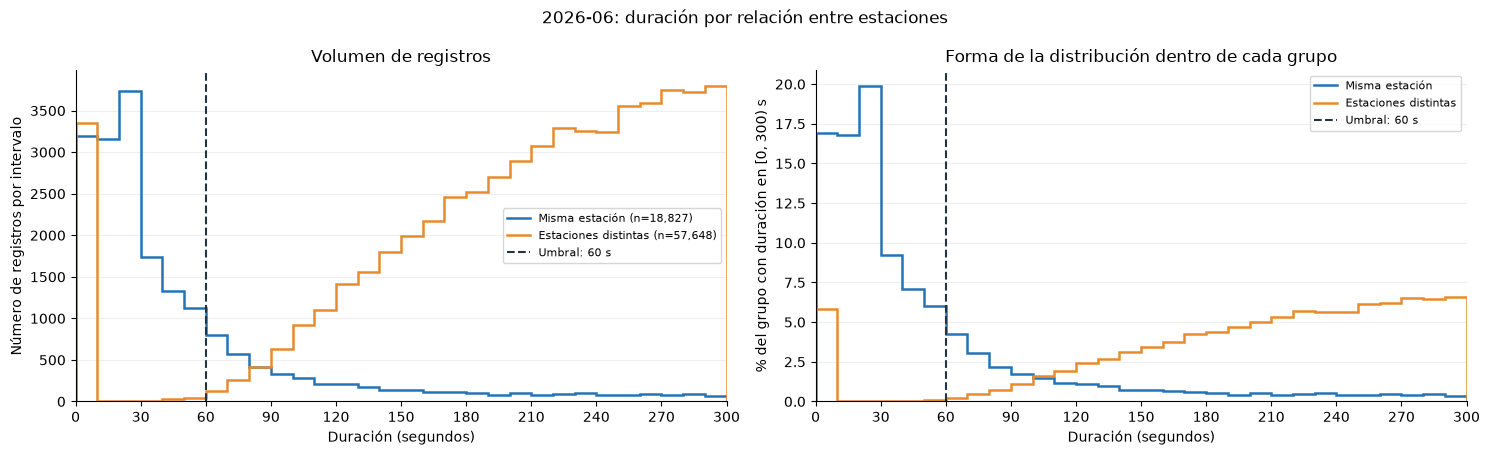

,limite_s_exclusivo,misma_estacion_desde_0s,estaciones_distintas_desde_0s
0,10,3189,3357
1,30,10095,3358
2,60,14288,3437
3,90,16074,4227
4,120,16900,6876



**Resultado y decisión.** Hay **14,288 registros en la misma estación** y
**3,437 entre estaciones distintas** desde cero hasta menos de 60 s.
Se observan **116 ceros**, de los cuales **22** son de la misma estación.
La regla de desanclaje está **activa** y excluye **14,266 filas**
después de los controles previos, no necesariamente el total señalado en el diagnóstico.

La concentración en pocos segundos permite revisar la hipótesis de intentos fallidos, sin demostrarla.
Como referencia, pasar de 60 a 90 s señalaría **1,786 registros originales adicionales**
de la misma estación. El umbral no debe ampliarse solo porque se observa concentración: también hay
que valorar la posible pérdida de viajes válidos. Los conteos de la tabla son acumulados y no se suman.


In [4]:
MES_DIAGNOSTICO = '2026_06' if '2026_06' in MESES else MESES[-1]
raw_diagnostico = cargar_mes(MES_DIAGNOSTICO)
diagnostico_detalle = anotar_viajes(raw_diagnostico, MES_DIAGNOSTICO, coords, POLITICA, IDS_ENTRE_ARCHIVOS)
seleccion_diagnostico, bitacora_diagnostico = seleccionar_viajes(diagnostico_detalle, POLITICA)
validar_resultado(raw_diagnostico, seleccion_diagnostico, bitacora_diagnostico, MES_DIAGNOSTICO, POLITICA)
segundos_diag = raw_diagnostico['duracion_min'] * 60
ids_completos_diag = raw_diagnostico[['origen_id', 'destino_id']].notna().all(axis=1)
misma_diag = raw_diagnostico['origen_id'].eq(raw_diagnostico['destino_id'])
universo_duracion_diag = ids_completos_diag & np.isfinite(segundos_diag) & segundos_diag.ge(0)
ventana_duracion_diag = universo_duracion_diag & segundos_diag.lt(300)
umbral_duracion_diag = POLITICA['min_misma_estacion_s']
bins_duracion_diag = np.arange(0, 301, 10)

fig_duracion_diag, ejes_duracion_diag = plt.subplots(1, 2, figsize=(15, 4.6))
for grupo, mascara, color in [('Misma estación', misma_diag, '#2474b5'),
                               ('Estaciones distintas', ~misma_diag, '#e78b2d')]:
    valores = segundos_diag[ventana_duracion_diag & mascara]
    conteos, bordes = np.histogram(valores, bins=bins_duracion_diag)
    ejes_duracion_diag[0].stairs(conteos, bordes, color=color, linewidth=1.8,
                                 label=f'{grupo} (n={len(valores):,})')
    porcentajes = conteos * 100 / len(valores) if len(valores) else np.zeros(len(conteos))
    ejes_duracion_diag[1].stairs(porcentajes, bordes, color=color, linewidth=1.8, label=grupo)
    assert int(conteos.sum()) == len(valores)
for ax in ejes_duracion_diag:
    ax.axvline(umbral_duracion_diag, color='#233343', linestyle='--', linewidth=1.5,
               label=f'Umbral: {umbral_duracion_diag:g} s')
    ax.set(xlabel='Duración (segundos)', xlim=(0, 300))
    ax.set_xticks(np.arange(0, 301, 30))
    ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True); ax.legend(fontsize=8)
ejes_duracion_diag[0].set(title='Volumen de registros', ylabel='Número de registros por intervalo')
ejes_duracion_diag[1].set(title='Forma de la distribución dentro de cada grupo',
                          ylabel='% del grupo con duración en [0, 300) s')
fig_duracion_diag.suptitle(f'{MES_DIAGNOSTICO.replace("_", "-")}: duración por relación entre estaciones')
fig_duracion_diag.tight_layout(); plt.show()

tabla_duracion_diag = []
for limite in sorted({10, 30, 60, 90, 120, umbral_duracion_diag}):
    menores = universo_duracion_diag & segundos_diag.lt(limite)
    tabla_duracion_diag.append({'limite_s_exclusivo': limite,
        'misma_estacion_desde_0s': int((menores & misma_diag).sum()),
        'estaciones_distintas_desde_0s': int((menores & ~misma_diag).sum())})
tabla_duracion_diag = pd.DataFrame(tabla_duracion_diag)
display(tabla_duracion_diag)
n_misma_diag = int((universo_duracion_diag & misma_diag & segundos_diag.lt(umbral_duracion_diag)).sum())
n_distintas_diag = int((universo_duracion_diag & ~misma_diag & segundos_diag.lt(umbral_duracion_diag)).sum())
n_ceros_diag = int((universo_duracion_diag & segundos_diag.eq(0)).sum())
n_ceros_misma_diag = int((universo_duracion_diag & segundos_diag.eq(0) & misma_diag).sum())
exclusiones_desanclaje_diag = int(bitacora_diagnostico.loc[
    bitacora_diagnostico['paso'].eq('misma_estacion_corta'), 'filas_excluidas'].sum())
incremento_90_diag = int((universo_duracion_diag & misma_diag & segundos_diag.ge(60) & segundos_diag.lt(90)).sum())
estado_desanclaje_diag = 'activa' if POLITICA['excluir_misma_estacion_corta'] else 'desactivada'
display(Markdown(f"""
**Resultado y decisión.** Hay **{n_misma_diag:,} registros en la misma estación** y
**{n_distintas_diag:,} entre estaciones distintas** desde cero hasta menos de {umbral_duracion_diag:g} s.
Se observan **{n_ceros_diag:,} ceros**, de los cuales **{n_ceros_misma_diag:,}** son de la misma estación.
La regla de desanclaje está **{estado_desanclaje_diag}** y excluye **{exclusiones_desanclaje_diag:,} filas**
después de los controles previos, no necesariamente el total señalado en el diagnóstico.

La concentración en pocos segundos permite revisar la hipótesis de intentos fallidos, sin demostrarla.
Como referencia, pasar de 60 a 90 s señalaría **{incremento_90_diag:,} registros originales adicionales**
de la misma estación. El umbral no debe ampliarse solo porque se observa concentración: también hay
que valorar la posible pérdida de viajes válidos. Los conteos de la tabla son acumulados y no se suman.
"""))

#### Velocidad implícita entre estaciones distintas

La velocidad se calcula como **distancia Haversine en línea recta / duración en horas**. La distancia
recta es una cota inferior de la ruta, por lo que una velocidad calculada muy alta señala una
inconsistencia entre tiempo y ubicación. Una velocidad calculada baja no garantiza que todo el registro
sea correcto. El límite de **30 km/h** es una decisión configurable que debe revisarse con información
del servicio y el tipo de bicicleta, no una imposibilidad física universal.

El universo evaluado contiene solo viajes entre estaciones distintas, de duración positiva y velocidad
finita, que **sobreviven a las reglas anteriores al paso de velocidad**. Así se excluyen previamente
errores esenciales y, con la política predeterminada, estaciones fuera del catálogo o sin coordenadas.
Los viajes sin ubicación no se cuentan como viajes lentos ni como velocidades imposibles.

La figura usa escala logarítmica en el número de registros para mostrar tanto el cuerpo de la distribución
como los casos escasos. La última barra agrupa **todas las velocidades de 100 km/h o más**; no indica
que esos registros tengan exactamente 100 km/h. Los percentiles y el máximo se calculan con las
velocidades originales, sin agrupar ni recortar. La tabla compara varios límites sobre el mismo universo.

,indicador,registros
0,Registros originales del mes,355303
1,Sobreviven a los pasos previos a velocidad (am...,338985
2,"Entre estaciones distintas, con duración posit...",1905
3,Universo evaluable de velocidad después de pas...,324408


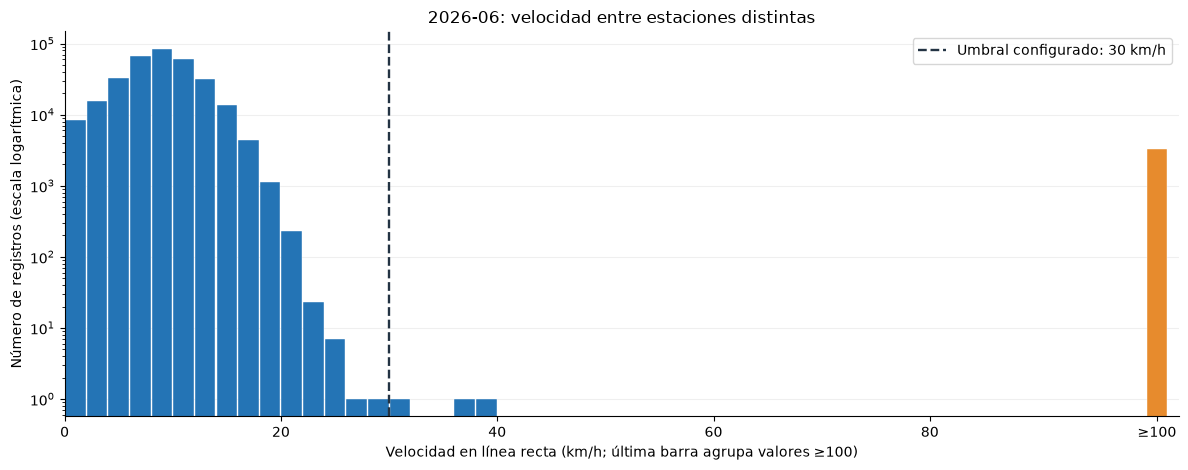

,km_h
cuantil,
0.50,8.89
0.90,13.20
0.95,14.71
0.99,221.98
1.00,19247.69


,limite_kmh,registros_por_encima,porcentaje_del_universo
0,25,3258,1.0043
1,30,3253,1.0027
2,40,3250,1.0018
3,60,3250,1.0018



**Resultado y decisión.** En los **324,408 registros evaluables**, la mediana es
**8.89 km/h** y el percentil 90 es **13.20 km/h**.
Se señalan **3,253** por encima de 30 km/h;
**3,250** alcanzan al menos 100 km/h en el cálculo en línea recta.
El paso de velocidad excluye **3,253 registros** con la política activa.

Entre 25 y 60 km/h, el conteo por encima del límite cambia en **8 registros** para este
mes y universo. Es una medida local de sensibilidad, no una prueba de que el umbral sea óptimo para todos
los periodos. La tabla y la evaluación posterior del modelo permiten revisar esa decisión.

**Relación con los viajes cortos.** Hay **3,329 viajes cortos entre estaciones
distintas** evaluables en este paso; **3,250** superan el límite de velocidad y
**79** no lo superan. Estos últimos siguen sujetos
a las demás reglas. Por ello, durar menos de un minuto no basta para excluir un viaje entre estaciones.


,regla,senalados_en_original,excluidos_en_su_paso
0,Misma estación y duración corta,14288,14266
1,Velocidad superior al umbral,3253,3253


**Cierre del diagnóstico.** Las dos reglas se complementan: una usa coincidencia de estación y tiempo; la otra incorpora distancia. Los indicadores originales pueden coincidir con otros problemas; las exclusiones de la bitácora se atribuyen a un único paso. La política conserva los registros anotados para revisar los supuestos y no asigna una causa operativa definitiva solo por estas gráficas.

In [5]:
aptos_antes_velocidad_diag = pd.Series(True, index=diagnostico_detalle.index)
for nombre_regla, bandera_regla, activa_regla in reglas_seleccion(POLITICA):
    if nombre_regla == 'velocidad_imposible':
        break
    if activa_regla:
        aptos_antes_velocidad_diag &= ~diagnostico_detalle[bandera_regla].fillna(False)
estaciones_distintas_diag = ~diagnostico_detalle['origen_id'].eq(diagnostico_detalle['destino_id'])
duracion_positiva_diag = diagnostico_detalle['duracion_min'].gt(0)
velocidad_finita_diag = np.isfinite(diagnostico_detalle['velocidad_kmh'])
evaluables_velocidad_diag = (aptos_antes_velocidad_diag & estaciones_distintas_diag &
                             duracion_positiva_diag & velocidad_finita_diag)
velocidades_diag = diagnostico_detalle.loc[evaluables_velocidad_diag, 'velocidad_kmh']
n_evaluables_velocidad_diag = len(velocidades_diag)
n_sin_velocidad_diag = int((estaciones_distintas_diag & duracion_positiva_diag & ~velocidad_finita_diag).sum())
display(pd.DataFrame([
    {'indicador': 'Registros originales del mes', 'registros': len(raw_diagnostico)},
    {'indicador': 'Sobreviven a los pasos previos a velocidad (ambos grupos)', 'registros': int(aptos_antes_velocidad_diag.sum())},
    {'indicador': 'Entre estaciones distintas, con duración positiva, sin velocidad finita en el original', 'registros': n_sin_velocidad_diag},
    {'indicador': 'Universo evaluable de velocidad después de pasos previos', 'registros': n_evaluables_velocidad_diag},
]))

if n_evaluables_velocidad_diag:
    umbral_velocidad_diag = POLITICA['max_velocidad_kmh']
    # Intervalos [0,2), ..., [98,100); el último [100,102] es una barra de desbordamiento.
    bordes_velocidad_diag = np.arange(0, 103, 2)
    conteos_velocidad_diag, bordes_velocidad_diag = np.histogram(
        np.minimum(velocidades_diag.to_numpy(), 100), bins=bordes_velocidad_diag)
    assert int(conteos_velocidad_diag.sum()) == n_evaluables_velocidad_diag
    fig_velocidad_diag, ax_velocidad_diag = plt.subplots(figsize=(12, 4.8))
    colores_velocidad_diag = ['#2474b5'] * (len(conteos_velocidad_diag)-1) + ['#e78b2d']
    ax_velocidad_diag.bar(bordes_velocidad_diag[:-1]+1, conteos_velocidad_diag, width=1.9,
                          color=colores_velocidad_diag, edgecolor='white', linewidth=0.3)
    ax_velocidad_diag.axvline(umbral_velocidad_diag, color='#233343', linestyle='--', linewidth=1.7,
                              label=f'Umbral configurado: {umbral_velocidad_diag:g} km/h')
    ax_velocidad_diag.set_yscale('log')
    ax_velocidad_diag.set(xlabel='Velocidad en línea recta (km/h; última barra agrupa valores ≥100)',
                           ylabel='Número de registros (escala logarítmica)', xlim=(0, 103),
                           title=f'{MES_DIAGNOSTICO.replace("_", "-")}: velocidad entre estaciones distintas')
    ax_velocidad_diag.set_xticks([0, 20, 40, 60, 80, 101], ['0', '20', '40', '60', '80', '≥100'])
    ax_velocidad_diag.grid(axis='y', alpha=0.2); ax_velocidad_diag.set_axisbelow(True)
    ax_velocidad_diag.legend(); fig_velocidad_diag.tight_layout(); plt.show()

    percentiles_velocidad_diag = velocidades_diag.quantile([0.50, 0.90, 0.95, 0.99]).rename_axis('cuantil').to_frame('km_h')
    percentiles_velocidad_diag.loc[1.0, 'km_h'] = velocidades_diag.max()
    display(percentiles_velocidad_diag.round(2))
    tabla_velocidad_diag = pd.DataFrame([
        {'limite_kmh': limite, 'registros_por_encima': int(velocidades_diag.gt(limite).sum()),
         'porcentaje_del_universo': 100*velocidades_diag.gt(limite).mean()}
        for limite in sorted({25, 30, 40, 60, umbral_velocidad_diag})])
    display(tabla_velocidad_diag.round(4))
    n_velocidad_senalados_diag = int(velocidades_diag.gt(umbral_velocidad_diag).sum())
    n_extremos_diag = int(velocidades_diag.ge(100).sum())
    excluidos_velocidad_diag = int(bitacora_diagnostico.loc[
        bitacora_diagnostico['paso'].eq('velocidad_imposible'), 'filas_excluidas'].sum())
    cortos_distintos_evaluables_diag = evaluables_velocidad_diag & diagnostico_detalle['corto_distinta_estacion']
    n_cortos_distintos_evaluables_diag = int(cortos_distintos_evaluables_diag.sum())
    n_cortos_rapidos_diag = int((cortos_distintos_evaluables_diag & diagnostico_detalle['flag_velocidad_imposible']).sum())
    cambio_25_60_diag = int(velocidades_diag.gt(25).sum() - velocidades_diag.gt(60).sum())
    display(Markdown(f"""
**Resultado y decisión.** En los **{n_evaluables_velocidad_diag:,} registros evaluables**, la mediana es
**{velocidades_diag.median():.2f} km/h** y el percentil 90 es **{velocidades_diag.quantile(.90):.2f} km/h**.
Se señalan **{n_velocidad_senalados_diag:,}** por encima de {umbral_velocidad_diag:g} km/h;
**{n_extremos_diag:,}** alcanzan al menos 100 km/h en el cálculo en línea recta.
El paso de velocidad excluye **{excluidos_velocidad_diag:,} registros** con la política activa.

Entre 25 y 60 km/h, el conteo por encima del límite cambia en **{cambio_25_60_diag:,} registros** para este
mes y universo. Es una medida local de sensibilidad, no una prueba de que el umbral sea óptimo para todos
los periodos. La tabla y la evaluación posterior del modelo permiten revisar esa decisión.

**Relación con los viajes cortos.** Hay **{n_cortos_distintos_evaluables_diag:,} viajes cortos entre estaciones
distintas** evaluables en este paso; **{n_cortos_rapidos_diag:,}** superan el límite de velocidad y
**{n_cortos_distintos_evaluables_diag-n_cortos_rapidos_diag:,}** no lo superan. Estos últimos siguen sujetos
a las demás reglas. Por ello, durar menos de un minuto no basta para excluir un viaje entre estaciones.
"""))
else:
    display(Markdown('**Sin registros evaluables de velocidad.** Revisar la cobertura, las coordenadas y los filtros previos.'))

comparacion_reglas_diag = pd.DataFrame([
    {'regla': 'Misma estación y duración corta',
     'senalados_en_original': int(diagnostico_detalle['flag_misma_estacion_corta'].sum()),
     'excluidos_en_su_paso': int(bitacora_diagnostico.loc[bitacora_diagnostico['paso'].eq('misma_estacion_corta'), 'filas_excluidas'].sum())},
    {'regla': 'Velocidad superior al umbral',
     'senalados_en_original': int(diagnostico_detalle['flag_velocidad_imposible'].sum()),
     'excluidos_en_su_paso': int(bitacora_diagnostico.loc[bitacora_diagnostico['paso'].eq('velocidad_imposible'), 'filas_excluidas'].sum())},
])
display(comparacion_reglas_diag)
display(Markdown('**Cierre del diagnóstico.** Las dos reglas se complementan: una usa coincidencia de estación y tiempo; '
                 'la otra incorpora distancia. Los indicadores originales pueden coincidir con otros problemas; '
                 'las exclusiones de la bitácora se atribuyen a un único paso. La política conserva los registros '
                 'anotados para revisar los supuestos y no asigna una causa operativa definitiva solo por estas gráficas.'))
del raw_diagnostico, diagnostico_detalle, seleccion_diagnostico

## 4. Comprobación de las reglas con casos límite

Antes de procesar los datos se verifica que las reglas produzcan las decisiones esperadas ante IDs
conflictivos, fechas fuera del mes, duplicados, coordenadas ausentes y duraciones exactamente en los límites.
También se comprueba que un viaje corto con desplazamiento plausible pueda conservarse, que las
correcciones demográficas mantengan el valor declarado y que el DataFrame de entrada no se modifique.


In [6]:
def probar_metodologia():
    c = pd.DataFrame({'latitude': [20.68, 20.68001, np.nan],
                      'longitude': [-103.35, -103.35001, np.nan]}, index=[1, 2, 3])
    base = {'usuario_id': 1, 'genero': 'F', 'anio_nacimiento': 2000,
            'inicio': pd.Timestamp('2026-06-01 10:00:00'), 'origen_id': 1, 'destino_id': 2}
    def fila(i, segundos, **cambios):
        f = dict(base, viaje_id=i)
        f.update(cambios)
        f['fin'] = f['inicio'] + pd.Timedelta(seconds=segundos) if pd.notna(f['inicio']) else pd.NaT
        return f
    filas = [fila(1, 600), fila(1, 600), fila(2, 600), fila(2, 700),
             fila(3, 0), fila(4, 59, destino_id=1), fila(5, 60, destino_id=1),
             fila(6, 10800), fila(7, 10801), fila(8, 600, destino_id=999),
             fila(9, 600, inicio=pd.Timestamp('2026-05-31 23:00')),
             fila(10, 600, anio_nacimiento=1800, genero='X'),
             fila(11, 30), fila(12, 600, destino_id=3), fila(13, 600),
             fila(14, 600, inicio=pd.NaT)]
    raw = pd.DataFrame(filas)[COLUMNAS]
    raw['duracion_min'] = (raw['fin'] - raw['inicio']).dt.total_seconds()/60
    antes = raw.copy(deep=True)
    anotado, b = seleccionar_viajes(anotar_viajes(raw, '2026_06', c, POLITICA, {13}), POLITICA)
    validar_resultado(raw, anotado, b, '2026_06', POLITICA)
    pd.testing.assert_frame_equal(raw, antes)
    assert set(anotado.loc[anotado['es_valido'], 'viaje_id']) == {1, 5, 6, 10, 11}
    assert anotado.loc[anotado['viaje_id'].eq(10), 'anio_nacimiento'].isna().all()
    assert anotado.loc[anotado['viaje_id'].eq(10), 'anio_nacimiento_original'].eq(1800).all()
    assert not anotado.loc[anotado['viaje_id'].eq(2), 'es_valido'].any()
    assert anotado.loc[anotado['viaje_id'].eq(11), 'corto_distinta_estacion'].all()
    # La fórmula conserva el límite configurado exactamente igual a una velocidad calculada.
    p_limite = dict(POLITICA, max_velocidad_kmh=float(anotado.loc[anotado['viaje_id'].eq(11), 'velocidad_kmh'].iloc[0]))
    assert not anotar_viajes(raw, '2026_06', c, p_limite).loc[raw['viaje_id'].eq(11), 'flag_velocidad_imposible'].any()
    # La política flexible conserva las anomalías de dominio pero no errores esenciales.
    flexible = dict(POLITICA, excluir_misma_estacion_corta=False, excluir_duracion_larga=False,
                    excluir_estacion_sin_catalogo=False, excluir_sin_coordenadas=False, excluir_velocidad=False)
    otra, b2 = seleccionar_viajes(anotar_viajes(raw, '2026_06', c, flexible, {13}), flexible)
    validar_resultado(raw, otra, b2, '2026_06', flexible)
    assert {4, 7, 8, 12}.issubset(set(otra.loc[otra['es_valido'], 'viaje_id']))
    return 'Pruebas de casos límite y conservación del original: correctas.'

print(probar_metodologia())


Pruebas de casos límite y conservación del original: correctas.


## 5. Aplicación mensual y efecto de las reglas

Se comparan dos políticas para cuantificar el efecto de las decisiones. La **base conservadora** aplica
integridad temporal, identificadores y deduplicación, conservando los registros señalados por reglas de
plausibilidad y disponibilidad geográfica. La **política final** agrega los filtros configurados de
duración, velocidad, catálogo y coordenadas. La diferencia muestra cuántos viajes dependen de esas reglas.

Una política no se considera mejor únicamente por conservar más registros. Debe ser consistente con
la definición de demanda y permitir justificar cada exclusión. Las estaciones históricas dadas de baja
se conservan cuando están catalogadas y sus viajes cumplen el resto de las reglas.

La corrección de edad o género no elimina el viaje. Los resúmenes presentan conteos agregados y la
bitácora permite comprobar la contribución de cada regla. La exportación de las vistas y el registro
en MLflow son opciones configurables, desactivadas en la ejecución mostrada.


In [7]:
POLITICA_BASE = dict(POLITICA, excluir_misma_estacion_corta=False, excluir_duracion_larga=False,
                     excluir_estacion_sin_catalogo=False, excluir_sin_coordenadas=False, excluir_velocidad=False)
resumenes, bitacoras, indicadores, diarios, horarios, semanales = [], [], [], [], [], []
manifest_salidas = []
RUN_DIR = None
if EXPORTAR_DATOS:
    import pyarrow
    sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
    RUN_DIR = PROJECT_DIR / 'data/interim/limpieza_integrada' / sello
    RUN_DIR.mkdir(parents=True, exist_ok=False)
    (RUN_DIR / 'anotados').mkdir()
    (RUN_DIR / 'validos').mkdir()

for mes in MESES:
    huella_esperada = manifest_entradas.loc[manifest_entradas['mes'].eq(mes), 'sha256'].iloc[0]
    if sha256_archivo(ruta_viajes(mes)) != huella_esperada:
        raise ValueError(f'El archivo {mes} cambió entre diagnóstico y limpieza.')
    raw = cargar_mes(mes)
    anotado = anotar_viajes(raw, mes, coords, POLITICA, IDS_ENTRE_ARCHIVOS)
    base, _ = seleccionar_viajes(anotado, POLITICA_BASE)
    n_base = int(base['es_valido'].sum())
    del base
    anotado, b = seleccionar_viajes(anotado, POLITICA)
    validar_resultado(raw, anotado, b, mes, POLITICA)
    valido = anotado.loc[anotado['es_valido']].copy()
    # Excluir duplicados exactos del denominador de indicadores; no filtrar otras anomalías.
    unico = anotado.loc[~anotado['flag_duplicado_exacto']]
    banderas = [c for c in anotado if c.startswith('flag_')] + ['viaje_corto', 'corto_distinta_estacion', 'duracion_larga']
    indicadores.extend({'mes': mes, 'indicador': c, 'filas': int(unico[c].sum()),
                        'denominador': len(unico), 'porcentaje': 100*unico[c].mean() if len(unico) else np.nan}
                       for c in banderas)
    resumenes.append({'mes': mes, 'originales': len(raw), 'sin_copias_exactas': len(unico),
        'base_conservadora': n_base, 'validos': len(valido), 'excluidos': len(raw)-len(valido),
        'pct_excluido': 100*(1-len(valido)/len(raw)) if len(raw) else np.nan,
        'estaciones_origen': valido['origen_id'].nunique(),
        'nacimientos_corregidos': int(valido['flag_edad_imposible'].sum() + valido['flag_nacimiento_no_numerico'].sum()),
        'generos_corregidos': int(valido['flag_genero_invalido'].sum())})
    bitacoras.append(b)
    # Incluir días sin viajes dentro de cada archivo; cero no significa automáticamente cero demanda real.
    inicio_mes = pd.Timestamp(mes.replace('_', '-') + '-01')
    calendario = pd.date_range(inicio_mes, inicio_mes + pd.offsets.MonthEnd(0), freq='D')
    d = valido.groupby(valido['inicio'].dt.normalize()).size().reindex(calendario, fill_value=0)
    diarios.append(d.rename('viajes_validos').rename_axis('fecha').reset_index().assign(mes=mes))
    horarios.append(valido['inicio'].dt.hour.value_counts().reindex(range(24), fill_value=0))
    semanales.append(valido['inicio'].dt.dayofweek.value_counts().reindex(range(7), fill_value=0))
    if EXPORTAR_DATOS:
        for carpeta, frame in [('anotados', anotado), ('validos', valido)]:
            destino = RUN_DIR / carpeta / f'viajes_{mes}.parquet'
            frame.to_parquet(destino, index=False)
            manifest_salidas.append({'archivo': destino.relative_to(RUN_DIR).as_posix(),
                                    'filas': len(frame), 'bytes': destino.stat().st_size,
                                    'sha256': sha256_archivo(destino)})
    print(f"{mes}: {len(raw):,} originales -> {len(valido):,} válidos; {len(raw)-len(valido):,} excluidos")
    del raw, anotado, unico, valido
    gc.collect()

resumen = pd.DataFrame(resumenes)
bitacora = pd.concat(bitacoras, ignore_index=True)
indicadores = pd.DataFrame(indicadores)
diarios = pd.concat(diarios, ignore_index=True)
if sha256_archivo(CATALOGO) != manifest_entradas.loc[manifest_entradas['tipo'].eq('catalogo'), 'sha256'].iloc[0]:
    raise ValueError('El catálogo cambió durante el procesamiento.')
resumen['dias_mes'] = pd.to_datetime(resumen['mes'], format='%Y_%m').dt.days_in_month
resumen['promedio_diario'] = resumen['validos']/resumen['dias_mes']
resumen['viajes_por_estacion_con_actividad'] = resumen['validos']/resumen['estaciones_origen'].replace(0, np.nan)
assert int(resumen['originales'].sum()-resumen['validos'].sum()) == int(bitacora['filas_excluidas'].sum())
display(resumen.round(3))
display(bitacora.groupby(['orden', 'paso'])['filas_excluidas'].sum().to_frame())
display(indicadores.pivot(index='mes', columns='indicador', values='porcentaje').round(3))


2025_01: 380,184 originales -> 370,915 válidos; 9,269 excluidos


2025_02: 372,529 originales -> 363,530 válidos; 8,999 excluidos


2025_03: 405,110 originales -> 394,765 válidos; 10,345 excluidos


2025_04: 366,193 originales -> 357,088 válidos; 9,105 excluidos


2025_05: 395,891 originales -> 385,864 válidos; 10,027 excluidos


...

2026_08: 393,524 originales -> 376,340 válidos; 17,184 excluidos


2026_09: 490,056 originales -> 470,480 válidos; 19,576 excluidos


,mes,originales,sin_copias_exactas,base_conservadora,validos,excluidos,pct_excluido,estaciones_origen,nacimientos_corregidos,generos_corregidos,dias_mes,promedio_diario,viajes_por_estacion_con_actividad
0,2025_01,380184,380184,379979,370915,9269,2.438,368,43,0,31,11965.000,1007.921
1,2025_02,372529,372529,372335,363530,8999,2.416,367,72,0,28,12983.214,990.545
2,2025_03,405110,405110,404894,394765,10345,2.554,367,49,0,31,12734.355,1075.654
3,2025_04,366193,366193,366008,357088,9105,2.486,367,44,0,30,11902.933,972.992
4,2025_05,395891,395891,395702,385864,10027,2.533,367,70,0,31,12447.226,1051.401
5,2025_06,356611,356611,356333,346867,9744,2.732,368,47,0,30,11562.233,942.573
6,2025_07,368186,368186,367933,358424,9762,2.651,367,59,0,31,11562.065,976.632
7,2025_08,374727,374727,374452,364639,10088,2.692,367,22,0,31,11762.548,993.567
8,2025_09,376789,376789,376561,366582,10207,2.709,367,0,0,30,12219.400,998.861
9,2025_10,420064,420064,419839,409509,10555,2.513,368,40,0,31,13209.968,1112.796


,,filas_excluidas
orden,paso,
1,id_esencial_nulo,0
2,fecha_invalida,0
3,inicio_fuera_mes,0
4,id_conflictivo,0
5,id_entre_archivos,0
6,duplicado_exacto,758
7,duracion_no_positiva,5814
8,misma_estacion_corta,221119
9,estacion_sin_catalogo,3888


indicador,corto_distinta_estacion,duracion_larga,flag_duplicado_exacto,flag_duracion_no_positiva,flag_edad_imposible,flag_estacion_sin_catalogo,flag_fecha_invalida,flag_fuera_mes,flag_genero_invalido,flag_id_conflictivo,flag_id_entre_archivos,flag_id_esencial_nulo,flag_misma_estacion_corta,flag_nacimiento_no_numerico,flag_sin_coordenadas,flag_velocidad_imposible,viaje_corto
mes,,,,,,,,,,,,,,,,,
2025_01,0.130,0.012,0.0,0.054,0.012,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.311,0.0,0.0,0.071,2.441
2025_02,0.129,0.011,0.0,0.052,0.021,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.291,0.0,0.0,0.073,2.421
2025_03,0.147,0.013,0.0,0.053,0.013,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.408,0.0,0.0,0.092,2.555
2025_04,0.114,0.005,0.0,0.051,0.013,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.381,0.0,0.0,0.063,2.495
2025_05,0.128,0.008,0.0,0.048,0.019,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.411,0.0,0.0,0.079,2.539
2025_06,0.208,0.014,0.0,0.078,0.013,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.519,0.0,0.0,0.137,2.727
2025_07,0.145,0.010,0.0,0.069,0.017,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.509,0.0,0.0,0.079,2.654
2025_08,0.153,0.009,0.0,0.073,0.006,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.542,0.0,0.0,0.086,2.695
2025_09,0.154,0.009,0.0,0.061,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,2.550,0.0,0.0,0.106,2.704


## 6. Sensibilidad a las reglas de duración y velocidad

Sobre junio de 2026 (o el último mes disponible) se cambia **un umbral a la vez** manteniendo el resto
de la política. Se reportan conteos; no se infiere que la política que conserva más filas sea mejor.
La decisión final exige evidencia operativa y evaluación del modelo con una partición temporal común.


In [8]:
MES_DETALLE = '2026_06' if '2026_06' in MESES else MESES[-1]
raw_detalle = cargar_mes(MES_DETALLE)
sensibilidad = []
for parametro, valores in [('min_misma_estacion_s', [30, 60, 90]),
                           ('max_velocidad_kmh', [25, 30, 40]),
                           ('max_duracion_min', [120, 180, 240])]:
    for valor in valores:
        p = dict(POLITICA, **{parametro: valor})
        a, b = seleccionar_viajes(anotar_viajes(raw_detalle, MES_DETALLE, coords, p, IDS_ENTRE_ARCHIVOS), p)
        validar_resultado(raw_detalle, a, b, MES_DETALLE, p)
        sensibilidad.append({'mes': MES_DETALLE, 'parametro': parametro, 'valor': valor,
                              'validos': int(a['es_valido'].sum()),
                              'es_configuracion_final': valor == POLITICA[parametro]})
sensibilidad = pd.DataFrame(sensibilidad)
display(sensibilidad)
del raw_detalle, a, b


,mes,parametro,valor,validos,es_configuracion_final
0,2026_06,min_misma_estacion_s,30,339848,False
1,2026_06,min_misma_estacion_s,60,335665,True
2,2026_06,min_misma_estacion_s,90,333883,False
3,2026_06,max_velocidad_kmh,25,335660,False
4,2026_06,max_velocidad_kmh,30,335665,True
5,2026_06,max_velocidad_kmh,40,335668,False
6,2026_06,max_duracion_min,120,335600,False
7,2026_06,max_duracion_min,180,335665,True
8,2026_06,max_duracion_min,240,335683,False


## 7. Patrones temporales, cobertura y días por investigar

Se normalizan los volúmenes mensuales por días de calendario. Las estaciones con al menos un origen
no equivalen a estaciones oficialmente operativas ni miden horas de servicio. No se imputan viajes
en días vacíos: primero hay que comprobar cobertura del archivo y operación.

Se etiqueta un día si su volumen es menor al 60% de la mediana del mismo día de semana dentro de su mes.
La mediana mensual es retrospectiva: sirve para auditoría, pero no debe usarse como predictor disponible
en tiempo real ni para filtrar automáticamente entrenamiento/prueba. Un día bajo puede ser festivo,
falla, clima u otra causa; este cálculo no establece la causa.


,fecha,viajes_validos,mes,dia_semana,referencia,proporcion,flag_dia_bajo,flag_sin_referencia,causa
0,2025-01-01,3306,2025_01,2,14534.0,0.227467,True,False,pendiente_verificacion
33,2025-02-03,8041,2025_02,0,14525.5,0.553578,True,False,pendiente_verificacion
75,2025-03-17,7820,2025_03,0,14658.0,0.533497,True,False,pendiente_verificacion
107,2025-04-18,6721,2025_04,4,12841.0,0.523402,True,False,pendiente_verificacion
120,2025-05-01,8044,2025_05,3,13788.0,0.583406,True,False,pendiente_verificacion
258,2025-09-16,6481,2025_09,1,14541.0,0.445705,True,False,pendiente_verificacion
320,2025-11-17,7718,2025_11,0,13978.5,0.552134,True,False,pendiente_verificacion
357,2025-12-24,7034,2025_12,2,12951.0,0.543124,True,False,pendiente_verificacion
358,2025-12-25,3014,2025_12,3,13074.0,0.230534,True,False,pendiente_verificacion
364,2025-12-31,7112,2025_12,2,12951.0,0.549147,True,False,pendiente_verificacion


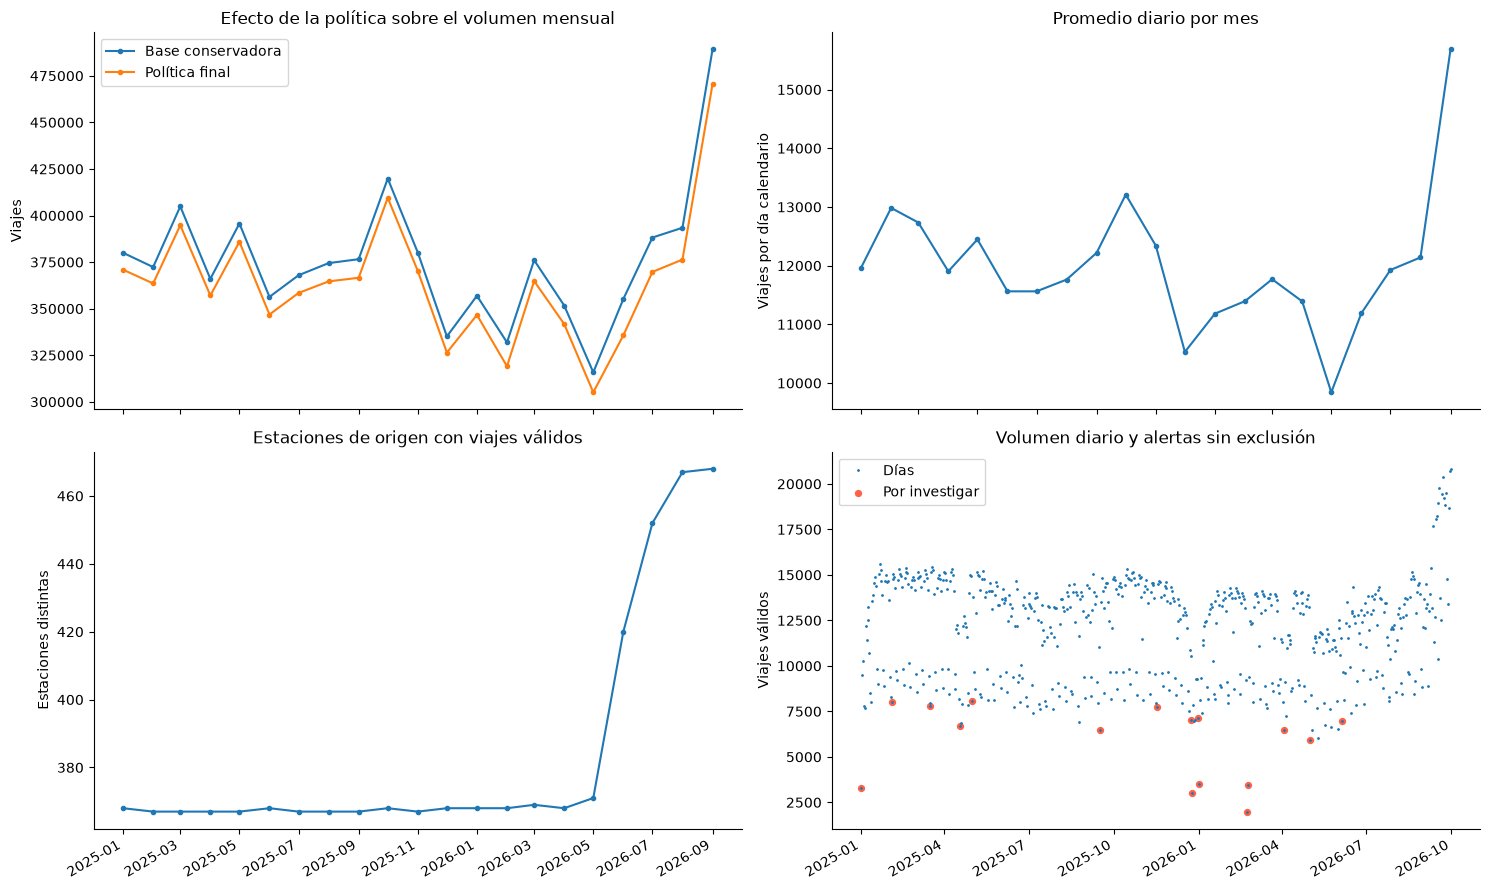

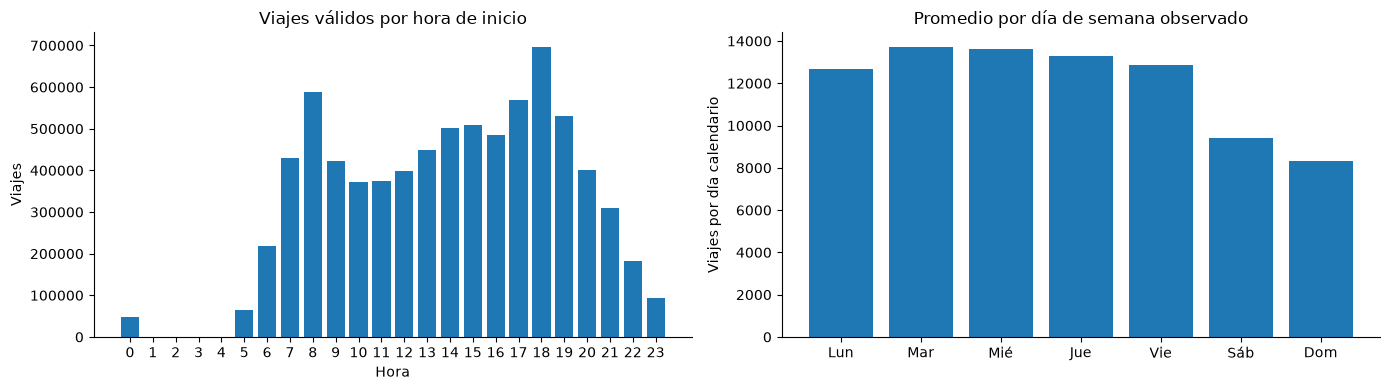

In [9]:
diarios['dia_semana'] = diarios['fecha'].dt.dayofweek
diarios['referencia'] = diarios.groupby(['mes', 'dia_semana'])['viajes_validos'].transform('median')
diarios['proporcion'] = diarios['viajes_validos']/diarios['referencia'].replace(0, np.nan)
diarios['flag_dia_bajo'] = diarios['proporcion'].lt(POLITICA['umbral_dia_bajo'])
diarios['flag_sin_referencia'] = diarios['referencia'].eq(0)
dias_revision = diarios.loc[diarios['flag_dia_bajo'] | diarios['flag_sin_referencia']].copy()
dias_revision['causa'] = 'pendiente_verificacion'
display(dias_revision)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
x = pd.to_datetime(resumen['mes'], format='%Y_%m')
axes[0, 0].plot(x, resumen['base_conservadora'], label='Base conservadora', marker='.')
axes[0, 0].plot(x, resumen['validos'], label='Política final', marker='.')
axes[0, 0].set(title='Efecto de la política sobre el volumen mensual', ylabel='Viajes'); axes[0, 0].legend()
axes[0, 1].plot(x, resumen['promedio_diario'], marker='.')
axes[0, 1].set(title='Promedio diario por mes', ylabel='Viajes por día calendario')
axes[1, 0].plot(x, resumen['estaciones_origen'], marker='.')
axes[1, 0].set(title='Estaciones de origen con viajes válidos', ylabel='Estaciones distintas')
axes[1, 1].plot(diarios['fecha'], diarios['viajes_validos'], '.', markersize=2, label='Días')
axes[1, 1].scatter(dias_revision['fecha'], dias_revision['viajes_validos'], color='tomato', s=18, label='Por investigar')
axes[1, 1].set(title='Volumen diario y alertas sin exclusión', ylabel='Viajes válidos'); axes[1, 1].legend()
fig.autofmt_xdate(); fig.tight_layout(); plt.show()

conteo_horas = pd.concat(horarios, axis=1).sum(axis=1).astype(int)
conteo_semana = pd.concat(semanales, axis=1).sum(axis=1).astype(int)
ocurrencias = diarios['dia_semana'].value_counts().reindex(range(7), fill_value=0)
promedio_semana = conteo_semana/ocurrencias.replace(0, np.nan)
fig2, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(24), conteo_horas); axes[0].set(title='Viajes válidos por hora de inicio', xlabel='Hora', ylabel='Viajes'); axes[0].set_xticks(range(24))
axes[1].bar(['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'], promedio_semana)
axes[1].set(title='Promedio por día de semana observado', ylabel='Viajes por día calendario')
fig2.tight_layout(); plt.show()


## 8. Trazabilidad, exportación opcional y MLflow

La identidad de la versión combina SHA-256 de cada entrada y catálogo, política, código del notebook,
`dataset.py` y versiones del entorno. La huella identifica contenido; **no guarda una copia de los datos**.
Para recuperar una versión hay que conservar los originales y/o los Parquet de la corrida.

Con `EXPORTAR_DATOS=True`, la sección 5 crea una carpeta nueva bajo
`data/interim/limpieza_integrada/` con vistas anotadas y válidas. Esta sección agrega bitácora, manifiestos,
indicadores, sensibilidad y política. Al cambiar esa opción, vuelve a ejecutar todo el notebook.

Con `REGISTRAR_MLFLOW=True` se registra la corrida en una base local dedicada, sin utilizar un servidor
remoto. Se registran parámetros, métricas, resúmenes y manifiestos; los Parquet quedan referenciados en el
almacenamiento local, no se duplican en MLflow. No se registra el historial completo de datos en Git.


**Entrega silver:** la materialización productiva se ejecuta con `python -m proyecto_mlops_equipo_9.cleaning --version version_001`. Genera `data/silver/version_001/` con Parquet, campos de control, originales demográficos, excluidos, bitácora y manifiestos. Las exportaciones opcionales descritas arriba son exploratorias y permanecen desactivadas. El módulo productivo no inicia runs de MLflow; su registro se realizará en una sesión asistida separada.


In [10]:
RUTA_NOTEBOOK = PROJECT_DIR / 'notebooks/1.2-integracion-limpieza-final.ipynb'
if not RUTA_NOTEBOOK.is_file():
    raise FileNotFoundError('Conserva el nombre del notebook final para identificar su código.')
contenido_notebook = json.loads(RUTA_NOTEBOOK.read_text(encoding='utf-8'))
fuentes = [''.join(c['source']) for c in contenido_notebook['cells'] if c['cell_type'] == 'code']
codigo_sha256 = hashlib.sha256('\n\n'.join(fuentes).encode('utf-8')).hexdigest()
entorno = {'python': platform.python_version(), **{p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'matplotlib']}}
identidad = {'entradas': manifest_entradas.to_dict(orient='records'), 'politica': POLITICA,
            'codigo_notebook_sha256': codigo_sha256,
            'dataset_py_sha256': sha256_archivo(PROJECT_DIR / 'proyecto_mlops_equipo_9/dataset.py'),
            'cleaning_py_sha256': sha256_archivo(PROJECT_DIR / 'proyecto_mlops_equipo_9/cleaning.py'), 'entorno': entorno}
version_datos = hashlib.sha256(json.dumps(identidad, sort_keys=True, ensure_ascii=False).encode('utf-8')).hexdigest()
print(f'Versión de datos y metodología: {version_datos}')
print('Exportación activada:', EXPORTAR_DATOS, '| Registro MLflow activado:', REGISTRAR_MLFLOW)
if EXPORTAR_DATOS:
    for nombre, frame in [('resumen_mensual', resumen), ('bitacora', bitacora),
                          ('indicadores', indicadores), ('calidad_original', calidad),
                          ('dias_revision', dias_revision), ('sensibilidad', sensibilidad),
                          ('manifest_entradas', manifest_entradas)]:
        frame.to_csv(RUN_DIR / f'{nombre}.csv', index=False, encoding='utf-8')
    pd.DataFrame(manifest_salidas).to_csv(RUN_DIR / 'manifest_salidas.csv', index=False)
    (RUN_DIR / 'version.json').write_text(json.dumps(dict(identidad, version_datos=version_datos),
                                                    ensure_ascii=False, indent=2), encoding='utf-8')
    print('Archivos preservados en:', RUN_DIR)

if REGISTRAR_MLFLOW:
    import mlflow
    db = PROJECT_DIR / 'mlflow_limpieza_integrada.db'
    mlflow.set_tracking_uri('sqlite:///' + db.as_posix())
    mlflow.set_experiment('mibici-limpieza-integrada')
    with mlflow.start_run(run_name='limpieza-final-' + version_datos[:12]):
        mlflow.set_tags({'version_datos': version_datos, 'codigo_sha256': codigo_sha256,
                         'almacenamiento_datos': str(RUN_DIR.resolve())})
        mlflow.log_params({**POLITICA, 'catalogo': CATALOGO.name, 'n_meses': len(MESES)})
        mlflow.log_metrics({'viajes_originales': int(resumen['originales'].sum()),
                            'viajes_validos': int(resumen['validos'].sum()),
                            'viajes_excluidos': int(resumen['excluidos'].sum()),
                            'dias_por_revisar': len(dias_revision)})
        for archivo in list(RUN_DIR.glob('*.csv')) + list(RUN_DIR.glob('*.json')):
            mlflow.log_artifact(str(archivo))
        print('MLflow run_id:', mlflow.active_run().info.run_id)


Versión de datos y metodología: 73f95f008a8605a623a550c8a80853e3f547381610a8bfc0af368a247ede470f
Exportación activada: False | Registro MLflow activado: False


## 9. Resultados y justificación de la política aplicada

Los resultados se calculan a partir de los archivos disponibles y las reglas configuradas. El número de
viajes aceptados depende de la cobertura mensual, los umbrales y la versión del catálogo.

La comparación de políticas permite distinguir los registros excluidos por integridad de las exclusiones
adicionales por plausibilidad y ubicación. Los indicadores y la sensibilidad ayudan a revisar estas decisiones;
los conteos por sí mismos no confirman causas operativas ni mejoras de predicción.


In [11]:
originales = int(resumen['originales'].sum())
validos = int(resumen['validos'].sum())
base_total = int(resumen['base_conservadora'].sum())
principal = bitacora.groupby('paso')['filas_excluidas'].sum().sort_values(ascending=False)
display(Markdown(f"""
Se procesaron **{len(MESES)} meses** y **{originales:,} registros originales**.
La política final conservó **{validos:,} viajes** y excluyó **{originales-validos:,}**
({100*(originales-validos)/originales:.3f}% del total).
La base conservadora contiene **{base_total:,} viajes**; las reglas de dominio explican
**{base_total-validos:,} exclusiones adicionales**. El paso con más exclusiones fue
**{principal.index[0]}**, con **{int(principal.iloc[0]):,} filas**.
Se identificaron **{len(dias_revision)} días por investigar**, sin excluirlos automáticamente.

**Validación:** todos los meses cumplieron el contrato de la política y el balance de filas.
Las pruebas sintéticas también comprobaron límites, conflictos y conservación del original.
"""))



Se procesaron **21 meses** y **7,894,097 registros originales**.
La política final conservó **7,644,409 viajes** y excluyó **249,688**
(3.163% del total).
La base conservadora contiene **7,887,525 viajes**; las reglas de dominio explican
**243,116 exclusiones adicionales**. El paso con más exclusiones fue
**misma_estacion_corta**, con **221,119 filas**.
Se identificaron **16 días por investigar**, sin excluirlos automáticamente.

**Validación:** todos los meses cumplieron el contrato de la política y el balance de filas.
Las pruebas sintéticas también comprobaron límites, conflictos y conservación del original.


### Criterios para revisar las reglas antes del modelado

1. Confirmar que el conteo de inicios de viajes aceptados representa la demanda que se quiere predecir.
2. Contrastar los límites de duración y velocidad con el funcionamiento del servicio, incluyendo bicicletas eléctricas.
3. Investigar estaciones sin ubicación e IDs en cuarentena; corregir los insumos con evidencia y generar otra versión.
4. Verificar los días de volumen bajo con calendario y registros operativos antes de decidir su tratamiento.
5. Comparar las políticas con la misma partición temporal de entrenamiento, validación y prueba.
6. Las reglas se importan de `cleaning.py`, que también materializa las versiones silver.
   Conservar sus pruebas y registrar cualquier cambio de política.

### Fundamento metodológico

La preparación se sostiene en cuatro criterios: **integridad del evento**, **consistencia temporal**,
**plausibilidad del desplazamiento** y **trazabilidad de las decisiones**. Los datos demográficos se corrigen
sin perder viajes, mientras que las condiciones que afectan la identificación, el tiempo o la ubicación
determinan su aceptación según la política. Las anomalías se conservan anotadas para permitir revisión.

Los resultados describen calidad y comportamiento de los datos. La evaluación posterior del modelo
permitirá valorar el efecto predictivo de las reglas. La exportación y el registro opcional en MLflow
requieren ejecutar las ramas correspondientes con sus opciones activadas.
